# 05 — Full run over the whole lightcone

This notebook processes all 67 slices (324 M galaxies, z = 0–4) and then looks at the complete
Roman-like parent catalog. It is meant for an exclusive CPU node (Perlmutter: 128 physical
cores, 512 GB): slices are processed in parallel, one per worker process, with a peak of a few GB
per worker. Wall time is dominated by reading the 340 GB of input from CFS.

The same run from the command line is
`romanmock run <config.yaml> --workers 32` (the notebook writes that config file).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

In [2]:
import time
from romanmock import RomanMockConfig, RomanMockPipeline

N_WORKERS = 32          # one slice per process; ~2-5 GB peak each for the largest slices
OUT_DIR = os.path.join(WORK, "full")

cfg = RomanMockConfig.from_dict({
    "catalog": {"path": CATALOG},                        # every slice, z = 0-4
    "output": {"dir": OUT_DIR, "overwrite": False,
               "passthrough_columns": ["gal_id", "ra", "dec", "redshift_true", "redshift_obs",
                                       "logsm_obs", "logssfr_obs", "roman_F158", "roman_Grism_1stOrder"]},
    "line_set": "roman_transitions",
    "sensitivity": {"type": "constant", "flux_limit": 1e-16, "wave_range": [10000.0, 19300.0]},
    "detection": {"type": "threshold"},
    "confusion": {"type": "matrix", "default_p_fail": 0.02, "rows": {      # assumed scenario, not a calibration
        "Ha":        {"OIII_5007": 0.05, "OII_3727": 0.03, "fail": 0.05},
        "OIII_5007": {"Ha": 0.15, "OII_3727": 0.05, "fail": 0.05},
        "OII_3727":  {"Ha": 0.15, "OIII_5007": 0.10, "fail": 0.10},
        "Hb":        {"Ha": 0.30, "OIII_5007": 0.30, "fail": 0.20}}},
    "seed": 2026,
})
os.makedirs(OUT_DIR, exist_ok=True)
cfg.to_yaml(os.path.join(OUT_DIR, "config.yaml"))     # reusable with: romanmock run .../config.yaml --workers 32
pipe = RomanMockPipeline(cfg)
print(pipe.line_set.describe())

LineSet 'roman_transitions': bit -> feature (rest wavelength [A]; components)
  bit  0 (value          1): Ha          6564.723  Ba_alpha_6563  H-alpha 6563
  bit  1 (value          2): Hb          4862.763  Ba_beta_4861  H-beta 4861
  bit  2 (value          4): OIII_5007   5008.314  O_III_5007  [O III] 5007
  bit  3 (value          8): OIII_4959   4960.370  O_III_4959  [O III] 4959
  bit  4 (value         16): OII_3727    3728.619  O_II_3726+O_II_3729  [O II] 3726+3729 blend
  bit  5 (value         32): SIII_9532   9533.378  S_III_9532  [S III] 9532
  bit  6 (value         64): SIII_9069   9071.246  S_III_9069  [S III] 9069
  bit  7 (value        128): OIII_4363   4364.294  O_III_4363  [O III] 4363 (auroral)
  bit  8 (value        256): SIII_6312   6313.902  S_III_6312  [S III] 6312 (auroral)


In [3]:
t0 = time.time()
outputs = pipe.run(n_workers=N_WORKERS)               # existing outputs are skipped (output.overwrite = False)
print(f"{len(outputs)} slices, {(time.time() - t0) / 60:.1f} min")

[romanmock] step  105  z=[3.548,3.631]  n=2,402,205 -> lc_cores-105.romanmock.hdf5: 2,898 galaxies (0.12%)


[romanmock] step  100  z=[3.763,3.855]  n=2,427,416 -> lc_cores-100.romanmock.hdf5: 2,707 galaxies (0.11%)


[romanmock] step  107  z=[3.427,3.548]  n=4,035,691 -> lc_cores-107.romanmock.hdf5: 5,434 galaxies (0.13%)


[romanmock] step  102  z=[3.631,3.763]  n=3,763,996 -> lc_cores-102.romanmock.hdf5: 4,085 galaxies (0.11%)


[romanmock] step   97  z=[3.855,4.000]  n=3,453,453 -> lc_cores-97.romanmock.hdf5: 2,901 galaxies (0.08%)


[romanmock] step  119  z=[3.036,3.102]  n=3,609,564 -> lc_cores-119.romanmock.hdf5: 5,877 galaxies (0.16%)


... (58 outputs left out)

[romanmock] step  253  z=[0.914,0.959]  n=5,784,971 -> lc_cores-253.romanmock.hdf5: 1,855,654 galaxies (32.08%)


[romanmock] step  279  z=[0.736,0.779]  n=4,871,597 -> lc_cores-279.romanmock.hdf5: 1,579,165 galaxies (32.42%)


[romanmock] step  235  z=[1.055,1.107]  n=7,270,235 -> lc_cores-235.romanmock.hdf5: 2,315,105 galaxies (31.84%)


66 slices, 0.8 min


## The parent catalog

All slices re-open as one `opencosmo.Lightcone`. Only the columns needed below are read.

In [4]:
from romanmock.diagnostics import outcome_summary
from romanmock.selection import sky_area_deg2

parent = pipe.open_parent()
area = sky_area_deg2(parent, nside=256)
print(f"{len(parent):,} galaxies with at least one detected line, z_range {parent.z_range}, area {area:.0f} deg²")
cols = ["z_obs", "redshift_obs", "id_outcome", "n_det", "line_true", "line_assigned"]
t0 = time.time()
pdata = parent.select(*cols).get_data("numpy", wrap_single=True)
print(f"read {len(cols)} columns in {time.time() - t0:.0f} s")
summary = outcome_summary(pdata)
for k, v in summary.items():
    print(f"  {k:<15s} {v:>12,}  ({100 * v / len(parent):5.2f}%)")

64,556,046 galaxies with at least one detected line, z_range (0.024464831804281495, 4.0), area 2116 deg²


read 6 columns in 1 s
  NOT_DETECTED               0  ( 0.00%)
  MULTI_LINE        30,804,054  (47.72%)
  SINGLE_CORRECT    29,246,016  (45.30%)
  SINGLE_MISID       2,881,250  ( 4.46%)
  SINGLE_FAILED      1,624,726  ( 2.52%)


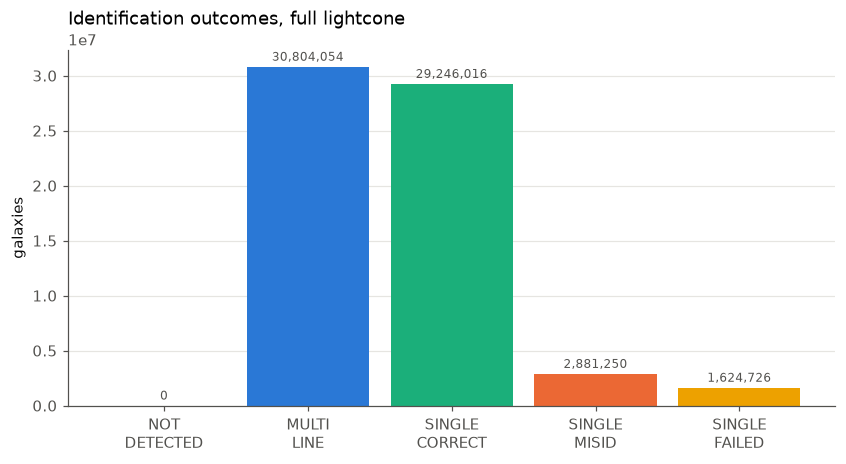

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
plotting.bar(ax, [k.replace("_", "\n") for k in summary], list(summary.values()), colors=[plotting.OUTCOME_COLORS[k] for k in summary])
ax.set_ylabel("galaxies"); ax.set_title("Identification outcomes, full lightcone"); plt.show()

## Redshift distributions per assigned line

`dN/dz_obs` per deg² of the galaxies *assigned* each identity (what an observer would call the
Hα sample, the [O III] sample, ...). Multi-line galaxies are counted under their brightest line.

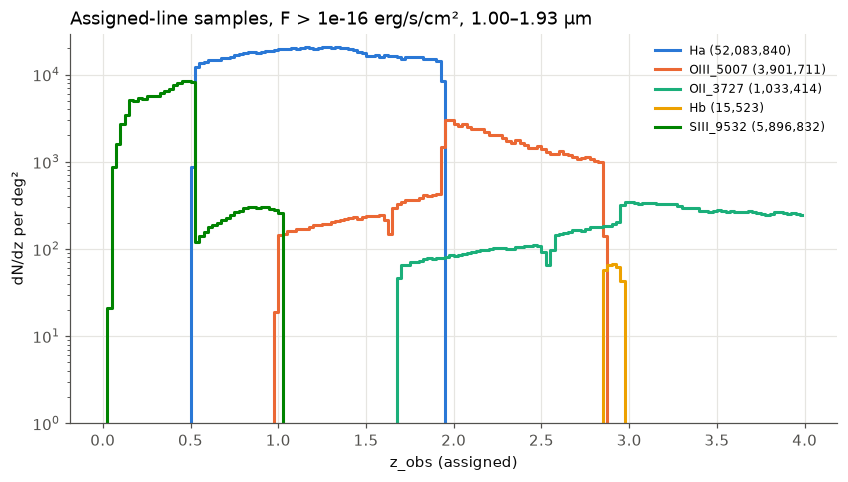

In [6]:
from romanmock.diagnostics import dndz

z_edges = np.linspace(0.0, 4.0, 161)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
has_z = np.isfinite(pdata["z_obs"])
fig, ax = plt.subplots(figsize=(9, 4.6))
for name in ["Ha", "OIII_5007", "OII_3727", "Hb", "OIII_4959", "SIII_9532"]:
    sel = has_z & (pdata["line_assigned"] == pipe.line_set.bit(name))
    if sel.sum() == 0:
        continue
    y = dndz(pdata["z_obs"][sel], z_edges, area)
    ax.step(zc, y, where="mid", color=plotting.feature_color(name), label=f"{name} ({sel.sum():,})")
ax.set_yscale("log"); ax.set_ylim(1, None)
ax.set_xlabel("z_obs (assigned)"); ax.set_ylabel("dN/dz per deg²"); ax.set_title("Assigned-line samples, F > 1e-16 erg/s/cm², 1.00–1.93 μm")
ax.legend(fontsize=8); plt.show()

## True versus assigned redshift

The density of galaxies in the (z_rsd, z_obs) plane. Correct identifications lie on the
diagonal; each interloper track is the line ``(1+z_obs) = (1+z_rsd) λ_i/λ_j``.

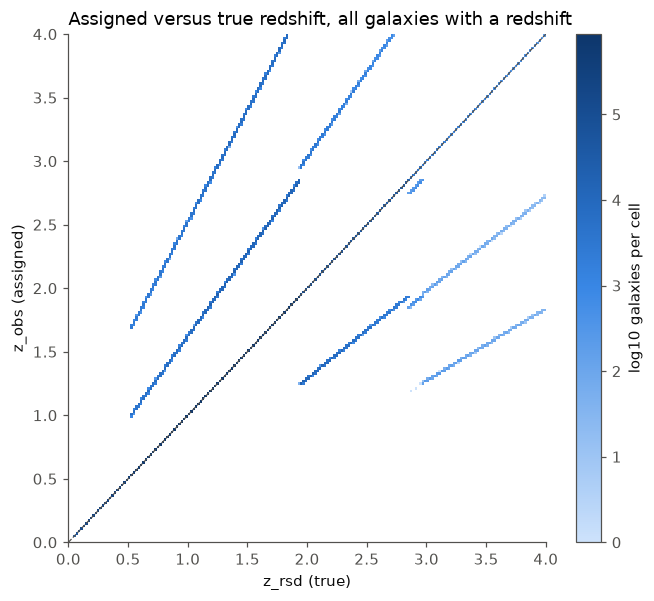

In [7]:
sel = has_z
H, xe, ye = np.histogram2d(pdata["redshift_obs"][sel], pdata["z_obs"][sel], bins=[np.linspace(0, 4, 201), np.linspace(0, 4, 201)])
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.pcolormesh(xe, ye, np.log10(np.where(H > 0, H, np.nan)).T, cmap=plotting.sequential_cmap())
plt.colorbar(im, ax=ax, label="log10 galaxies per cell")
ax.plot([0, 4], [0, 4], color=plotting.TEXT_SECONDARY, lw=0.8, ls="--")
ax.set_xlabel("z_rsd (true)"); ax.set_ylabel("z_obs (assigned)"); ax.set_title("Assigned versus true redshift, all galaxies with a redshift")
ax.grid(False); plt.show()

## Contamination of the Hα and [O III] samples

`f_{i→j}(B)`: the fraction of the assigned-*j* sample in a bin of z_obs whose true line is *i*
(plan comment 4). It depends on the confusion matrix *and* on the relative abundances of the
populations along the line of sight, so it is not constant even though the matrix is.

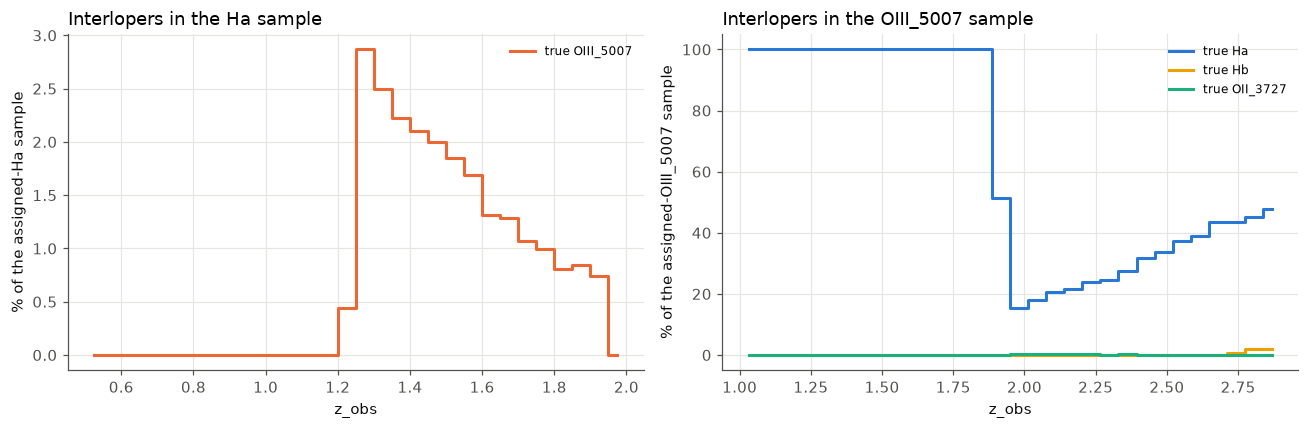

In [8]:
from romanmock.diagnostics import contamination_fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (assigned, zr) in zip(axes, [("Ha", (0.5, 2.0)), ("OIII_5007", (1.0, 2.9))]):
    edges = np.linspace(*zr, 31)
    c = contamination_fraction(pdata, pipe.line_set, edges, assigned_line=assigned)
    zc = 0.5 * (edges[1:] + edges[:-1])
    for name in pipe.line_set.names:
        i = pipe.line_set.bit(name)
        if name == assigned or c["fraction"][i].max() < 0.002:
            continue
        ax.step(zc, 100 * c["fraction"][i], where="mid", color=plotting.feature_color(name), label=f"true {name}")
    ax.set_xlabel("z_obs"); ax.set_ylabel(f"% of the assigned-{assigned} sample"); ax.set_title(f"Interlopers in the {assigned} sample")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Two features of these curves are properties of the mock rather than of the confusion matrix.
Below z_obs ≈ 1.9 the assigned-[O III] sample is *entirely* Hα interlopers: any galaxy whose
[O III] 5007 is detected there also has Hα (always brighter in diffsky) inside the bandpass, so it
is a multi-line detection and is counted under Hα; the only single-line "[O III]" objects are
misidentified Hα emitters. Likewise the [O III] → Hα contamination of the Hα sample switches on
at z_obs ≈ 1.2, where true [O III] emitters at z ≈ 1.9 (Hα just redshifted out of the grism)
start to be single-line detections.

## Completeness and the empirical confusion matrix

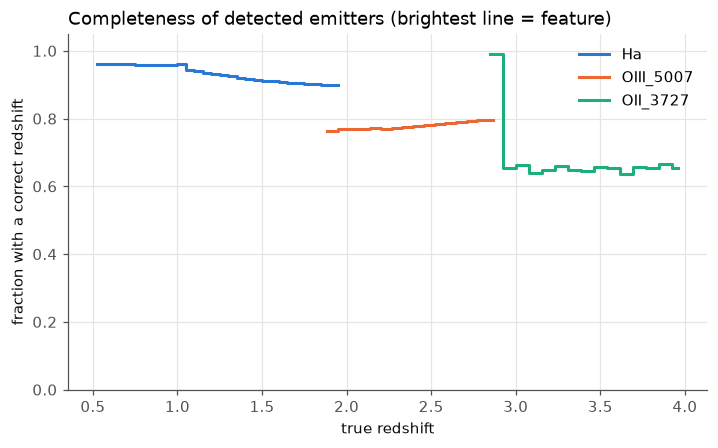

empirical confusion among single-line galaxies (rows true, columns assigned):
                   Ha        Hb OIII_5007 OIII_4959  OII_3727 SIII_9532 SIII_9069 OIII_4363 SIII_6312      fail
  Ha           0.8700    0.0000    0.0500    0.0000    0.0300    0.0000    0.0000    0.0000    0.0000    0.0500
  Hb           0.2998    0.2041    0.2952    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.2008
  OIII_5007    0.1502    0.0000    0.7500    0.0000    0.0498    0.0000    0.0000    0.0000    0.0000    0.0500
  OIII_4959    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
  OII_3727     0.1468    0.0000    0.1003    0.0000    0.6519    0.0000    0.0000    0.0000    0.0000    0.1010
  SIII_9532    0.0000    0.0000    0.0000    0.0000    0.0000    0.9800    0.0000    0.0000    0.0000    0.0200
  SIII_9069    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
  OIII_4363    0.0000    0

In [9]:
from romanmock.diagnostics import completeness, empirical_confusion

fig, ax = plt.subplots()
for name, zr in [("Ha", (0.5, 2.0)), ("OIII_5007", (1.0, 2.9)), ("OII_3727", (1.7, 4.0))]:
    edges = np.linspace(*zr, 31)
    comp = completeness(pdata, pipe.line_set, edges, line=name)
    ax.step(0.5 * (edges[1:] + edges[:-1]), comp["completeness"], where="mid", color=plotting.feature_color(name), label=name)
ax.set_ylim(0, 1.05); ax.set_xlabel("true redshift"); ax.set_ylabel("fraction with a correct redshift")
ax.set_title("Completeness of detected emitters (brightest line = feature)"); ax.legend(); plt.show()

emp = empirical_confusion(pdata, pipe.line_set)
names = pipe.line_set.names + ["fail"]
print("empirical confusion among single-line galaxies (rows true, columns assigned):")
print("            " + " ".join(f"{n[:9]:>9s}" for n in names))
for i, n in enumerate(pipe.line_set.names):
    print(f"  {n[:9]:<9s} " + " ".join(f"{x:9.4f}" for x in emp[i]))

## Analysis samples

Two HLSS-like tracer samples over the full footprint. The downsampling target below is a smooth
curve at half the mock density, standing in for a survey forecast; replace it with
`DownsampleConfig(target_file="forecast_dndz.txt")` (two columns: z, dN/dz per deg²) when one is
available. Bins where the target exceeds the mock are kept entirely and reported.

In [10]:
from romanmock.config import SampleConfig, DownsampleConfig
from scipy.ndimage import gaussian_filter1d

def half_mock_target(name, z_min, z_max, nbins=40):
    edges = np.linspace(z_min, z_max, nbins + 1)
    sel = has_z & (pdata["line_assigned"] == pipe.line_set.bit(name))
    mock = gaussian_filter1d(dndz(pdata["z_obs"][sel], edges, area), 1.5, mode="nearest")
    return {"z": (0.5 * (edges[1:] + edges[:-1])).tolist(), "dndz": (0.5 * mock).tolist()}, edges

tgt_ha, edges_ha = half_mock_target("Ha", 1.0, 1.9)
tgt_o3, edges_o3 = half_mock_target("OIII_5007", 2.0, 2.9)
samples = [
    SampleConfig(name="halpha_z1p0_1p9", z_min=1.0, z_max=1.9, assigned_lines=["Ha"],
                 downsample=DownsampleConfig(target=tgt_ha, z_edges=edges_ha.tolist(), area_deg2=area, smooth_bins=1.0)),
    SampleConfig(name="oiii_z2p0_2p9", z_min=2.0, z_max=2.9, assigned_lines=["OIII_5007"],
                 downsample=DownsampleConfig(target=tgt_o3, z_edges=edges_o3.tolist(), area_deg2=area, smooth_bins=1.0)),
]
cfg.output.overwrite = True
t0 = time.time()
sample_files = pipe.build_samples(samples=samples)
print(f"{(time.time() - t0) / 60:.1f} min")
sample_files

[romanmock] sample 'halpha_z1p0_1p9': area 2115.70 deg^2, p_keep range 0.496-0.507
[romanmock] sample 'halpha_z1p0_1p9': 17,222,736 of 64,556,046 parent galaxies


[romanmock] sample 'oiii_z2p0_2p9': area 2115.70 deg^2, p_keep range 0.455-1.000
[romanmock] sample 'oiii_z2p0_2p9': 1,502,743 of 64,556,046 parent galaxies


/global/u2/w/willlake/Packages/RomanMock/romanmock/pipeline.py:321: RuntimeWarning: target dN/dz exceeds the mock in 1 of 40 bins (z ~ 2.89-2.89); those bins are kept entirely.
  sub_keep, p_keep = downsample_to_dndz(z_sel, target, area, z_edges, rng, mock_dndz_values=mock)


1.5 min


[PosixPath('/pscratch/sd/w/willlake/romanmock_demo/full/samples/halpha_z1p0_1p9.hdf5'),
 PosixPath('/pscratch/sd/w/willlake/romanmock_demo/full/samples/oiii_z2p0_2p9.hdf5')]

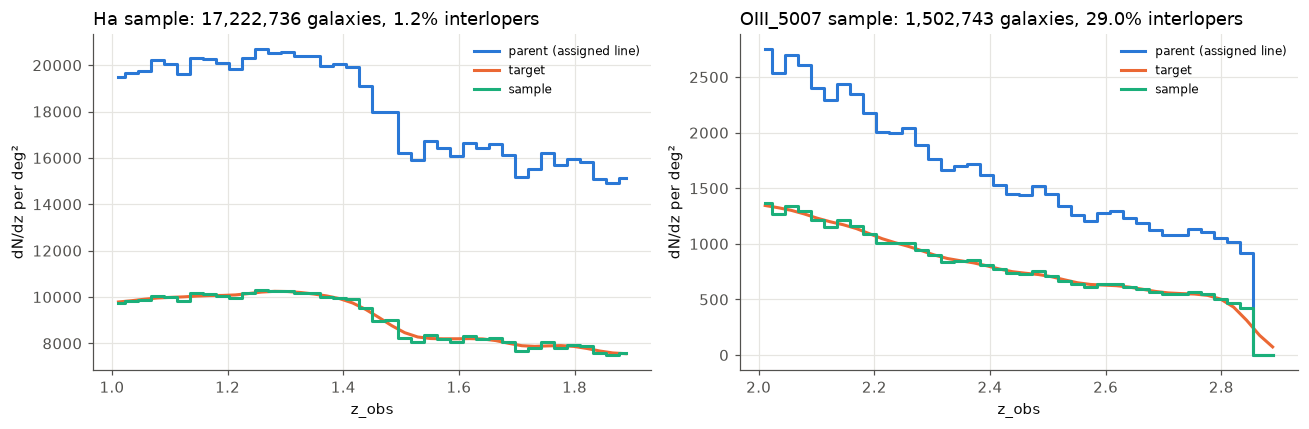

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, path, (tgt, edges), name in zip(axes, sample_files, [(tgt_ha, edges_ha), (tgt_o3, edges_o3)], ["Ha", "OIII_5007"]):
    ds = oc.open(path)
    d = ds.select("z_obs", "id_outcome").get_data("numpy", wrap_single=True)
    zc = 0.5 * (edges[1:] + edges[:-1])
    sel = has_z & (pdata["line_assigned"] == pipe.line_set.bit(name))
    ax.step(zc, dndz(pdata["z_obs"][sel], edges, area), where="mid", color=plotting.CATEGORICAL[0], label="parent (assigned line)")
    ax.plot(tgt["z"], tgt["dndz"], color=plotting.CATEGORICAL[1], label="target")
    ax.step(zc, dndz(d["z_obs"], edges, area), where="mid", color=plotting.CATEGORICAL[2], label="sample")
    misid = np.mean(d["id_outcome"] == 3)
    ax.set_xlabel("z_obs"); ax.set_ylabel("dN/dz per deg²"); ax.set_title(f"{name} sample: {len(d['z_obs']):,} galaxies, {100 * misid:.1f}% interlopers")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The sample files retain `gal_id`, `redshift_obs` (z_rsd), `z_obs`, `line_bitmask`, `line_true`,
`line_assigned` and `id_outcome`, so completeness, contamination and clustering can be checked
against the truth (plan section 4). Open them with `opencosmo.open(path)`.